# Gaussian processes and Bayesian optimisation, in one dimension

Figures for the presentation. One function to **maximise** on $[0,1]$, evaluated a few times, with noise.

1. **What a Gaussian process is**: the same model after 4, 7 and 12 evaluations (mean, uncertainty band, functions drawn from it).
2. **What the acquisition function recommends**: expected improvement (EI) computed from the GP, and the point it picks next, at four steps of the loop.

Everything uses the project's own code (`ContinuousGP`, `LogEIProduct`, `optimize`). Figures are saved in `presentation_figs/`.

In [1]:
import sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

for folder in (Path.cwd(), Path.cwd().parent):          # find the package next to or above this notebook
    if (folder / "BOproj").is_dir():
        sys.path.insert(0, str(folder))
        break

from BOproj.acquisition import LogEIProduct, optimize
from BOproj.gp import ContinuousGP

warnings.filterwarnings("ignore")
FIGURES = Path("presentation_figs")
FIGURES.mkdir(exist_ok=True)

# deck palette (purple of the slides) + one accent for everything the acquisition does
PURPLE, PURPLE_LIGHT, ACCENT, INK, GREY, RED, GREEN = "#371D77", "#9A86C9", "#E8743B", "#1E1E2A", "#6B6B7B", "#D7191C", "#1B9E77"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 13, "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.labelsize": 13, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": INK, "xtick.color": GREY, "ytick.color": GREY, "legend.frameon": False,
})

## The problem

A black-box function that is expensive to evaluate and returns noisy values: $y = f(x) + \varepsilon$, $\varepsilon \sim \mathcal N(0, 0.1^2)$. Two peaks, the narrow one on the right is the global maximum. Four evaluations to start.

In [2]:
BOUNDS = [[0.0, 1.0]]
NOISE_SD = 0.1
GRID = np.linspace(0, 1, 400)

def objective(x):
    # (negated) Forrester function: a smooth, multimodal test function, to be maximised
    x = np.asarray(x, dtype=float)
    return -((6 * x - 2) ** 2 * np.sin(12 * x - 4))

def evaluate(x, rng):
    # one noisy experiment
    return objective(x) + NOISE_SD * rng.standard_normal(np.shape(x))

rng = np.random.default_rng(3)
X_initial = np.array([0.1, 0.35, 0.6, 0.9])
y_initial = evaluate(X_initial, rng)
print("true maximum:", objective(GRID).max().round(2), "at x =", GRID[objective(GRID).argmax()].round(3))

true maximum: 6.02 at x = 0.757


## One BO loop, stored step by step

Each step: fit the GP on the data so far, compute EI on the grid, take the maximiser as the next evaluation. The GP is fitted **once per step** and kept, both figures below only plot what is stored here.

In [3]:
def fit_gp(X, y):
    return ContinuousGP(bounds=BOUNDS, noise=NOISE_SD ** 2).fit(X.reshape(-1, 1), y)

def expected_improvement(gp, best_value, grid):
    # EI of BoTorch (log version), back to the natural scale for plotting
    acquisition = LogEIProduct(gp, best_f=best_value)
    with torch.no_grad():
        return acquisition(torch.as_tensor(grid.reshape(-1, 1, 1))).exp().numpy()

def run_bo(X_start, y_start, n_steps, seed=0):
    # list of snapshots; snapshot k = everything known when the (k+1)-th point is chosen
    X, y, snapshots = X_start.copy(), y_start.copy(), []
    rng = np.random.default_rng(seed)
    for _ in range(n_steps):
        gp = fit_gp(X, y)
        mean, variance = gp.predict(GRID.reshape(-1, 1))
        incumbent = y.max()
        ei = expected_improvement(gp, incumbent, GRID)
        x_next, _ = optimize(LogEIProduct(gp, best_f=incumbent), BOUNDS, d=1)
        snapshots.append(dict(X=X.copy(), y=y.copy(), gp=gp, mean=mean, sd=np.sqrt(variance),
                              incumbent=incumbent, ei=ei, x_next=float(x_next[0])))
        X, y = np.append(X, x_next[0]), np.append(y, evaluate(x_next[0], rng))
    return snapshots

snapshots = run_bo(X_initial, y_initial, n_steps=12)
print("points chosen:", np.round([s["x_next"] for s in snapshots], 2))
print("best value found:", snapshots[-1]["y"].max().round(2))

points chosen: [0.   0.15 0.49 0.24 0.13 0.68 0.71 0.73 0.75 0.74 0.74 0.74]
best value found: 5.88


## 1. What a Gaussian process is

A distribution over functions. Given the data, it returns for every $x$ a **mean** $\mu(x)$ (best guess) and a **standard deviation** $\sigma(x)$ (how unsure). The band is $\mu \pm 1.96\,\sigma$. The thin lines are functions drawn from the posterior: all of them are compatible with the data, and they spread out where the data says little.

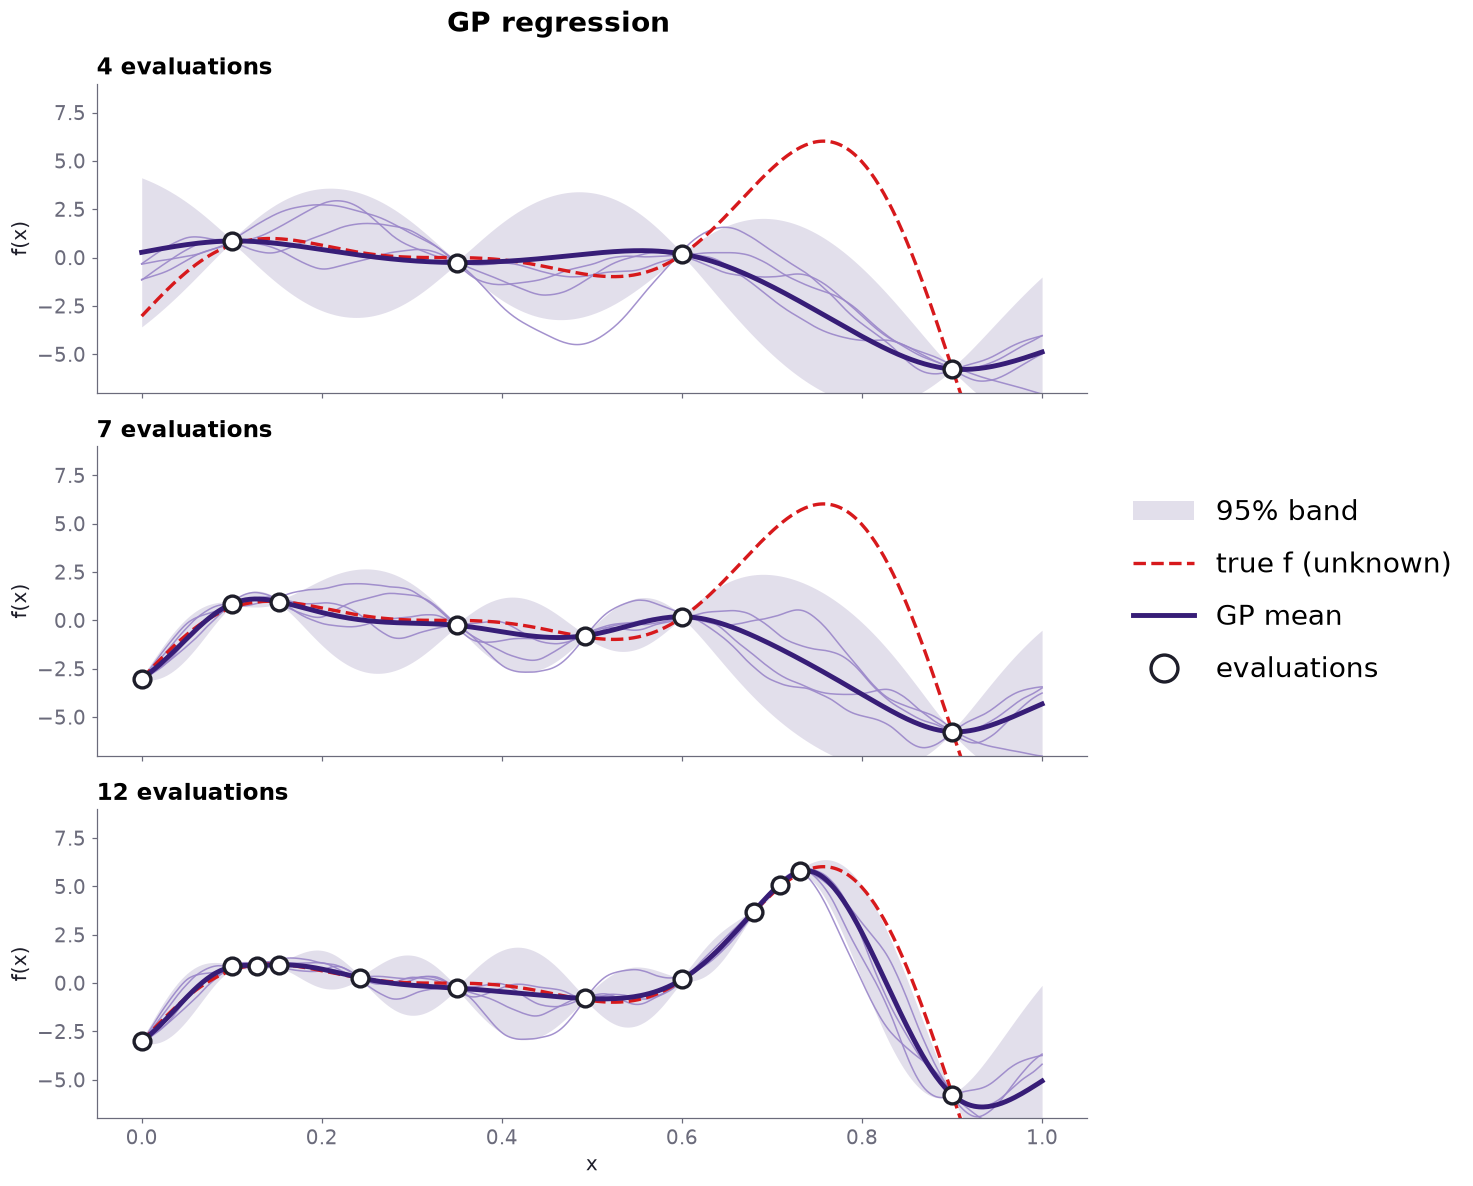

In [4]:
def draw_gp(ax, snapshot, show_truth=True, n_samples=4, seed=1, markersize=11):
    # mean, 95% band, posterior draws, data of one snapshot on one axis
    mean, sd, X, y = snapshot["mean"], snapshot["sd"], snapshot["X"], snapshot["y"]
    ax.fill_between(GRID, mean - 1.96 * sd, mean + 1.96 * sd, color=PURPLE, alpha=0.14, lw=0, label="95% band")
    if n_samples > 0:
        for draw in snapshot["gp"].sample(GRID.reshape(-1, 1), n=n_samples, seed=seed):
            ax.plot(GRID, draw, color=PURPLE_LIGHT, lw=1.0, alpha=0.9)
    if show_truth:
        ax.plot(GRID, objective(GRID), color=RED, lw=2.2, ls="--", label="true f (unknown)")
    ax.plot(GRID, mean, color=PURPLE, lw=3.2, label="GP mean")
    ax.plot(X, y, "o", color=INK, mfc="white", mew=2.2, ms=markersize, label="evaluations", zorder=5)

fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharey=True, sharex=True)
for ax, n_points in zip(axes, (4, 7, 12)):
    snapshot = snapshots[n_points - 4]                       # snapshot k holds 4 + k points
    draw_gp(ax, snapshot)
    ax.set_title(f"{n_points} evaluations", loc="left")
    ax.set_ylabel("f(x)")
axes[-1].set_xlabel("x")
axes[0].set_ylim(-7, 9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=18, markerscale=1.6, handlelength=2.2, labelspacing=0.9)
fig.suptitle("GP regression", fontsize=18, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "gp_few_and_many.png", bbox_inches="tight")
plt.show()

## 2. What the acquisition function recommends

Top: the GP and the best value seen so far (dotted). Bottom: **expected improvement**, the expected amount by which a new evaluation at $x$ would beat that best value,
$$\mathrm{EI}(x) = \mathbb E\big[\max(f(x) - y^*, 0)\big]$$
It is large where the mean is high (exploit) **or** where the band is wide (explore). The cross is the maximiser of EI: the next experiment.

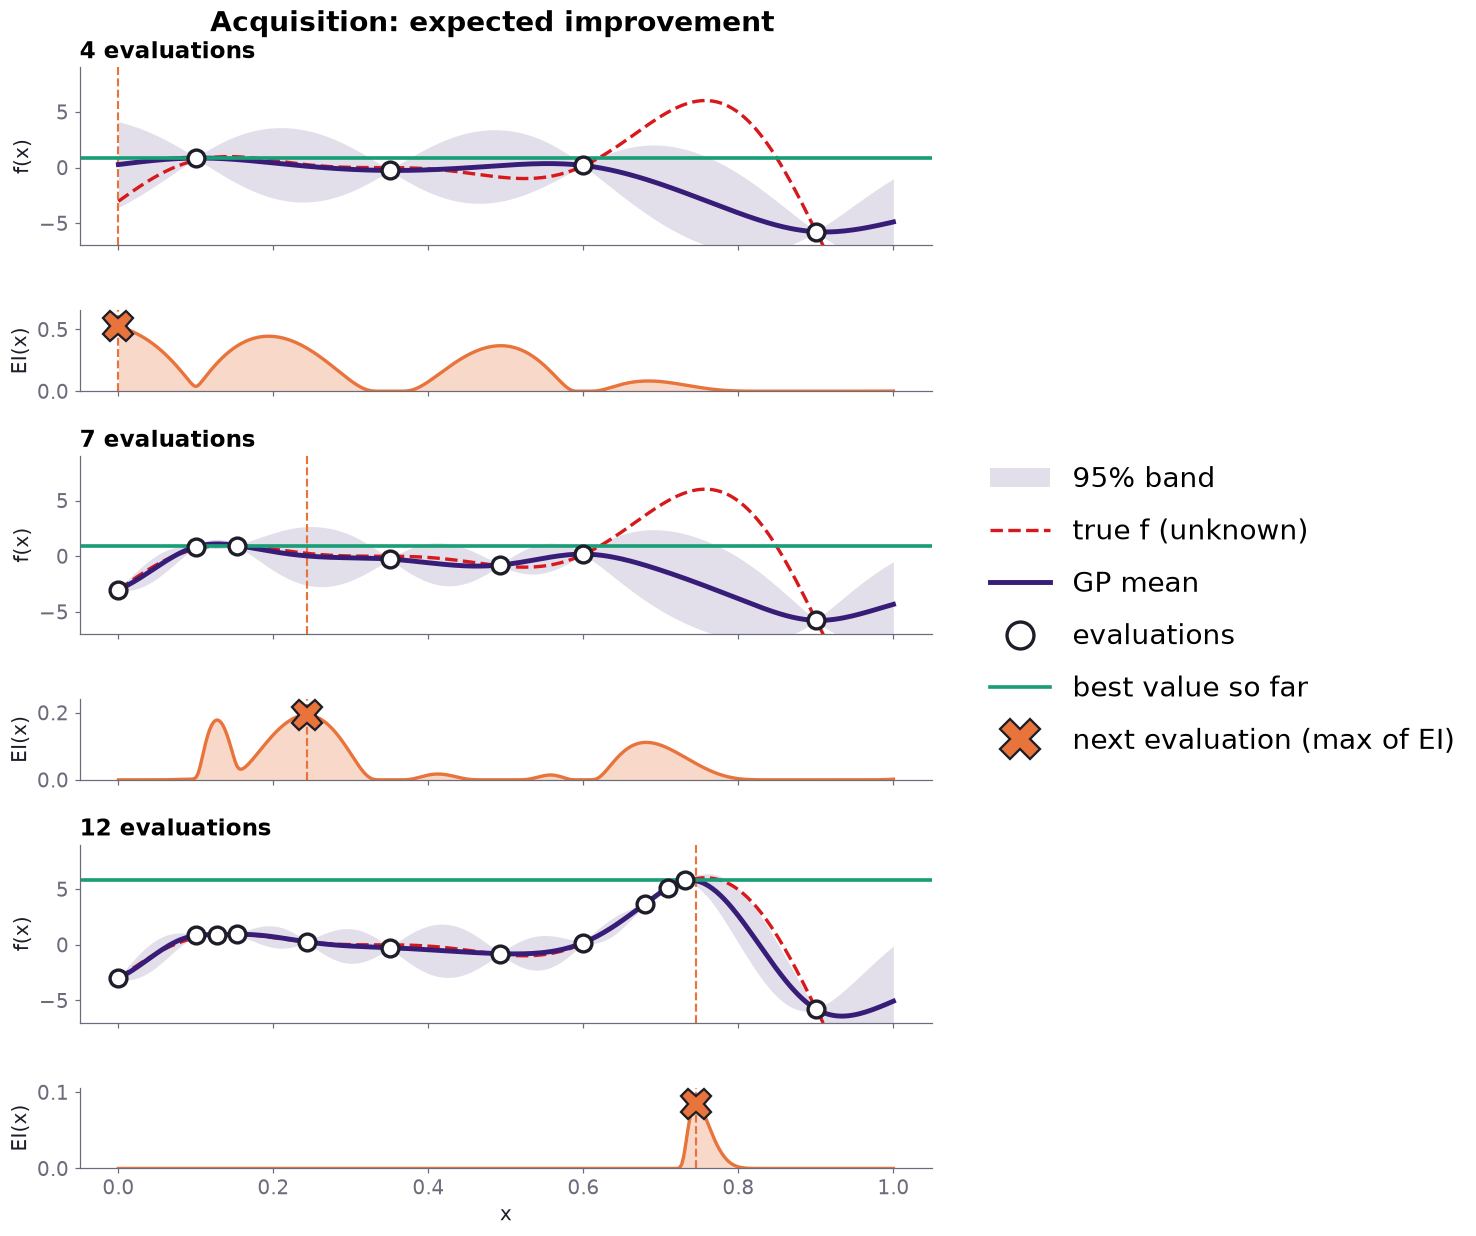

In [5]:
def draw_acquisition(ax, snapshot):
    ax.fill_between(GRID, 0, snapshot["ei"], color=ACCENT, alpha=0.28, lw=0)
    ax.plot(GRID, snapshot["ei"], color=ACCENT, lw=2.2)
    ax.plot(snapshot["x_next"], snapshot["ei"].max(), "X", color=ACCENT, mec=INK, mew=1.5, ms=20, zorder=6, clip_on=False)
    ax.set_ylim(0, 1.25 * snapshot["ei"].max())       # headroom: the cross is not cut off

steps = (0, 3, 8)                                            # snapshots shown: 4, 7 and 12 evaluations in hand
fig = plt.figure(figsize=(10, 13))
grid_spec = fig.add_gridspec(2 * len(steps), 1, height_ratios=[2.2, 1] * len(steps), hspace=0.5)
for row, step in enumerate(steps):
    snapshot = snapshots[step]
    gp_axis = fig.add_subplot(grid_spec[2 * row])
    ei_axis = fig.add_subplot(grid_spec[2 * row + 1], sharex=gp_axis)
    draw_gp(gp_axis, snapshot, n_samples=0)
    gp_axis.axhline(snapshot["incumbent"], color=GREEN, lw=2.4, ls="-", label="best value so far", zorder=2)
    gp_axis.axvline(snapshot["x_next"], color=ACCENT, lw=1.4, ls="--", zorder=1)
    gp_axis.set_ylim(-7, 9)
    gp_axis.set_ylabel("f(x)")
    gp_axis.set_title(f"{len(snapshot['X'])} evaluations", loc="left")
    gp_axis.tick_params(labelbottom=False)
    draw_acquisition(ei_axis, snapshot)
    ei_axis.axvline(snapshot["x_next"], color=ACCENT, lw=1.4, ls="--", zorder=1)
    ei_axis.set_ylabel("EI(x)")
    if row == 0:
        handles, labels = gp_axis.get_legend_handles_labels()
        handles.append(plt.Line2D([], [], marker="X", color=ACCENT, mec=INK, mew=1.5, ls="", ms=16))
        labels.append("next evaluation (max of EI)")
        fig.legend(handles, labels, loc="center left", bbox_to_anchor=(0.93, 0.5), fontsize=18, markerscale=1.6, handlelength=2.2, labelspacing=0.9)
    if row == len(steps) - 1:
        ei_axis.set_xlabel("x")
    else:
        ei_axis.tick_params(labelbottom=False)
fig.suptitle("Acquisition: expected improvement", fontsize=18, fontweight="bold", y=0.92)
fig.savefig(FIGURES / "acquisition_steps.png", bbox_inches="tight")
plt.show()

## 3. Learning preferences from comparisons

The decision maker never gives a score. Shown two designs $x$ and $y$, they only say which one they prefer. Here the DM is **noise-free**: they always pick the design with the higher (hidden) utility $u(x) = \sin 3x + x/2$ on $[0,3]$.

A second GP is fitted to these answers. Its latent function $g(x)$ is a utility scale learned from the comparisons, and it yields $P(x \succ y)$ for **every pair** of designs, including pairs nobody was ever asked about. Left: the truth (1 where $u(x) > u(y)$). Right: the GP, after 5, 10, 30 and 100 comparisons (the first 5, 10 and 30 of the same 100 answers).

In [6]:
from BOproj.gp import PreferenceGP

BOUNDS_PREF = [[0.0, 3.0]]
N_COMPARISONS = (5, 10, 30, 100)
PAIR_GRID = np.linspace(*BOUNDS_PREF[0], 120)

def utility(x):
    x = np.asarray(x, dtype=float).reshape(-1)
    return np.sin(3 * x) + 0.5 * x

def noise_free_comparisons(n_comparisons, n_designs=30, seed=3):
    # n_comparisons random pairs among n_designs random designs; the DM always picks the higher utility
    rng = np.random.default_rng(seed)
    designs = rng.uniform(*BOUNDS_PREF[0], (n_designs, 1))
    first = rng.integers(0, n_designs, n_comparisons)
    second = (first + rng.integers(1, n_designs, n_comparisons)) % n_designs
    return designs[first], designs[second], utility(designs[first]) > utility(designs[second])

def true_probability_matrix(grid):
    # entry [i, k] = P(grid[i] beats grid[k]) for the noise-free DM: 1, 0, or 0.5 on the diagonal
    u = utility(grid)
    return np.where(u[:, None] > u[None, :], 1.0, np.where(u[:, None] < u[None, :], 0.0, 0.5))

def fitted_probability_matrix(preference_gp, grid):
    # entry [i, k] = P(grid[i] beats grid[k]) from the GP: Phi(m / sqrt(2 + v)), m and v = mean and variance of g(x) - g(y)
    X = torch.as_tensor(grid.reshape(-1, 1))
    return preference_gp.prob_better_matrix_torch(X, X).detach().numpy()

all_xa, all_xb, all_first_wins = noise_free_comparisons(max(N_COMPARISONS))
preference_gps = {n: PreferenceGP(bounds=BOUNDS_PREF, link="probit").fit(all_xa[:n], all_xb[:n], all_first_wins[:n])
                  for n in N_COMPARISONS}                                  # each model fitted once
print("fitted:", list(preference_gps))

fitted: [5, 10, 30, 100]


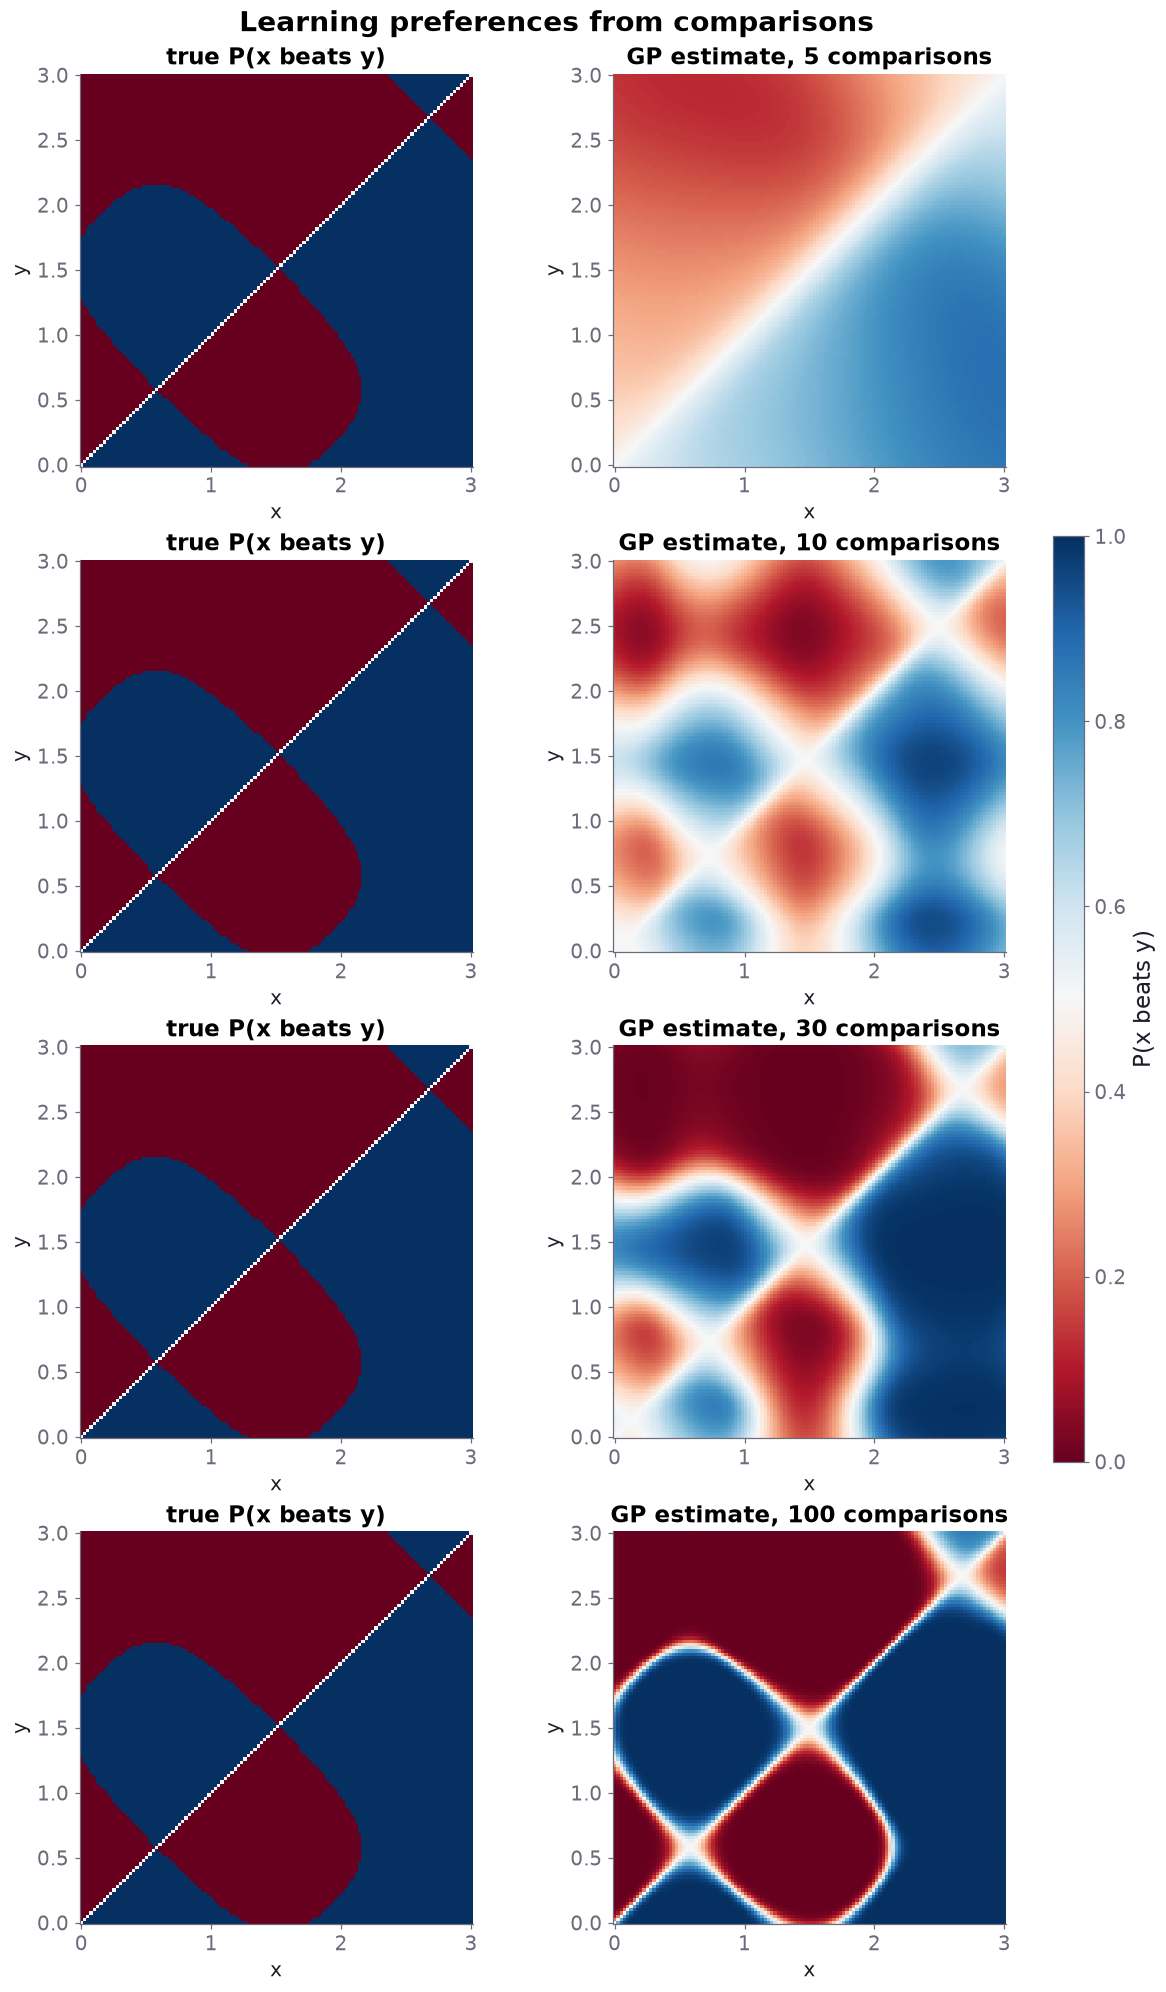

In [7]:
PREFERENCE_CMAP = plt.get_cmap("RdBu")                  # red: y wins, blue: x wins

def draw_pairs(ax, matrix, title, mappable_only=False):
    # matrix[i, k] = P(grid[i] beats grid[k]); x runs along the horizontal axis, y along the vertical one
    image = ax.pcolormesh(PAIR_GRID, PAIR_GRID, matrix.T, cmap=PREFERENCE_CMAP, vmin=0, vmax=1, shading="auto", rasterized=True)
    ax.set_title(title, fontsize=15)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_aspect("equal")
    return image

truth_matrix = true_probability_matrix(PAIR_GRID)
fig, axes = plt.subplots(len(N_COMPARISONS), 2, figsize=(11, 18), layout="constrained")
for row, n in zip(axes, N_COMPARISONS):
    draw_pairs(row[0], truth_matrix, "true P(x beats y)")
    image = draw_pairs(row[1], fitted_probability_matrix(preference_gps[n], PAIR_GRID), f"GP estimate, {n} comparisons")
colorbar = fig.colorbar(image, ax=axes, shrink=0.5, pad=0.04, aspect=30)
colorbar.set_label("P(x beats y)", fontsize=15)
colorbar.ax.tick_params(labelsize=13)
fig.suptitle("Learning preferences from comparisons", fontsize=18, fontweight="bold")
fig.savefig(FIGURES / "preference_pairs.png", bbox_inches="tight")
plt.show()

## 4. Bayes in general: a conjugate example

A coin lands heads with unknown probability $\theta$. We flip it $n$ times and see $k$ heads.

- **Prior** $p(\theta) = \mathrm{Beta}(a, b)$: belief about $\theta$ before flipping ($a = b = 2$: probably not extreme).
- **Likelihood** $p(\text{data} \mid \theta) \propto \theta^{k} (1-\theta)^{n-k}$: how probable the flips are for each $\theta$.
- **Posterior** $p(\theta \mid \text{data}) \propto$ likelihood $\times$ prior $= \mathrm{Beta}(a + k,\; b + n - k)$.

Prior and likelihood have the same shape ($\theta^{\cdot}(1-\theta)^{\cdot}$), so the posterior is in the same family as the prior: the prior is **conjugate** to the likelihood, and updating is just adding counts. The Gaussian prior with Gaussian noise of the next section is the other classic conjugate pair.

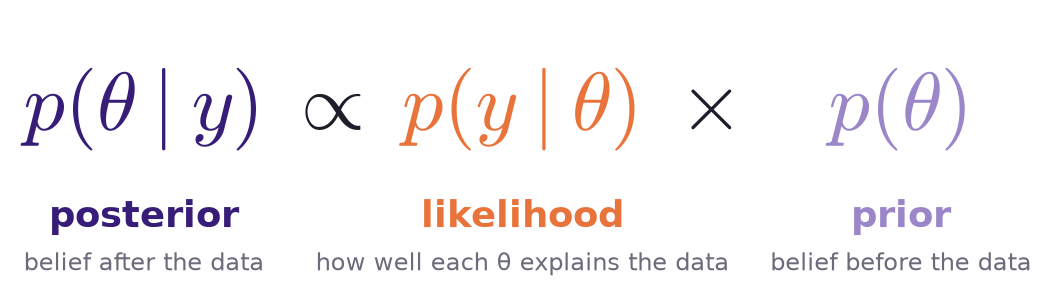

In [8]:
terms = (  # (x position, formula, name, description, colour)
    (0.13, r"$p(\theta \mid y)$", "posterior", "belief after the data", PURPLE),
    (0.50, r"$p(y \mid \theta)$", "likelihood", "how well each θ explains the data", ACCENT),
    (0.87, r"$p(\theta)$", "prior", "belief before the data", PURPLE_LIGHT),
)
with plt.rc_context({"mathtext.fontset": "cm"}):
    fig, ax = plt.subplots(figsize=(12, 3.2))
    ax.axis("off")
    for x_position, formula, name, description, colour in terms:
        ax.text(x_position, 0.62, formula, ha="center", va="center", fontsize=54, color=colour)
        ax.text(x_position, 0.20, name, ha="center", va="center", fontsize=24, fontweight="bold", color=colour)
        ax.text(x_position, 0.02, description, ha="center", va="center", fontsize=16, color=GREY)
    ax.text(0.315, 0.62, r"$\propto$", ha="center", va="center", fontsize=54, color=INK)
    ax.text(0.685, 0.62, r"$\times$", ha="center", va="center", fontsize=54, color=INK)
    ax.set_xlim(0, 1); ax.set_ylim(-0.05, 1)
    fig.savefig(FIGURES / "bayes_formula.png", bbox_inches="tight", facecolor="white")
    plt.show()

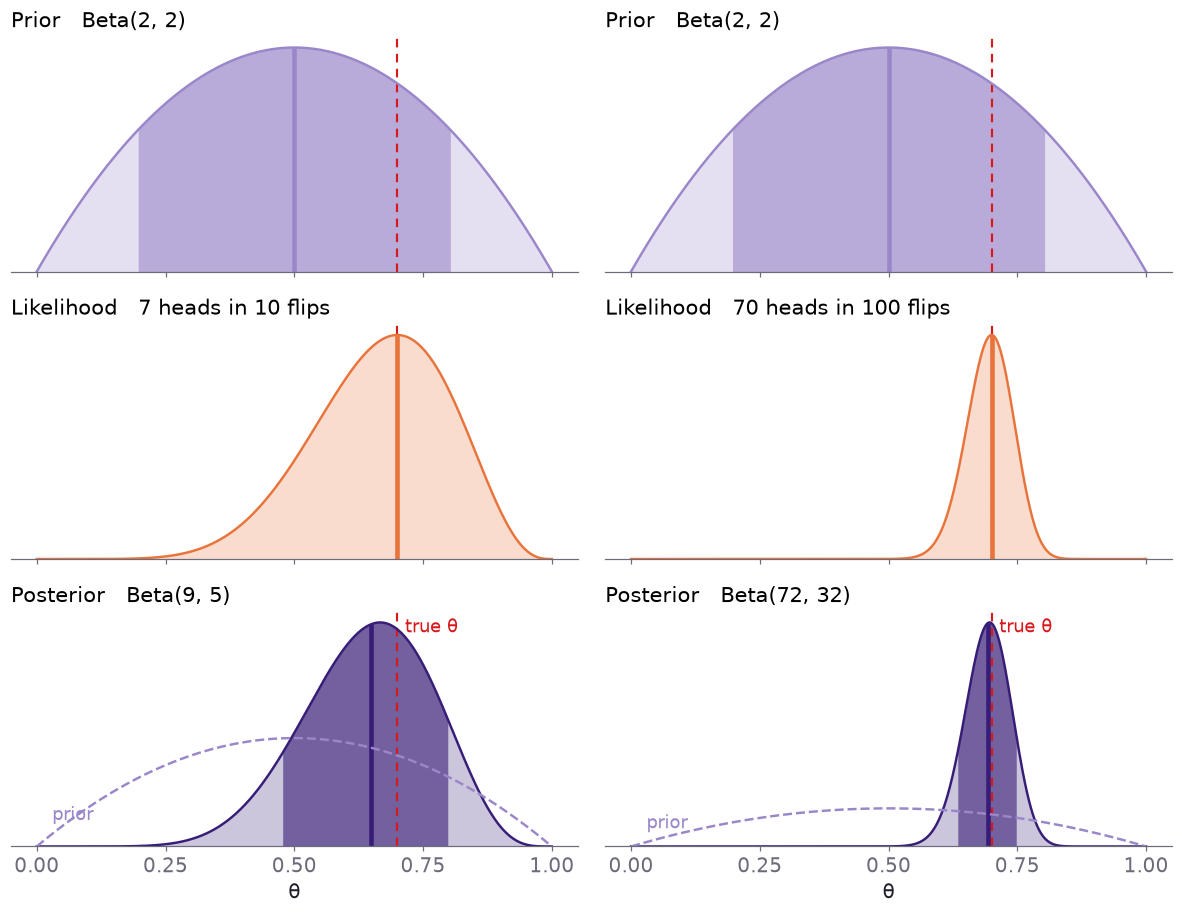

In [9]:
from scipy.stats import beta as beta_distribution

THETA = np.linspace(0, 1, 600)
TRUE_THETA = 0.7
PRIOR_A, PRIOR_B = 2, 2
FLIP_RESULTS = ((7, 10), (70, 100))          # (heads, flips): the same 70% heads, ten times more data

def draw_density(ax, density, color, interval=None):
    # bayesplot / rstan look: light area, darker central interval, a line at its centre, no y axis, no box
    ax.fill_between(THETA, density, color=color, alpha=0.25, lw=0)
    if interval is not None:
        low, centre, high = interval
        inside = (THETA >= low) & (THETA <= high)
        if inside.sum() > 1:
            ax.fill_between(THETA[inside], density[inside], color=color, alpha=0.6, lw=0)
        ax.vlines(centre, 0, np.interp(centre, THETA, density), color=color, lw=3)
    ax.plot(THETA, density, color=color, lw=1.6)
    ax.set_ylim(bottom=0)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)

def central_interval(a, b, mass=0.8):
    low, centre, high = beta_distribution.ppf([(1 - mass) / 2, 0.5, (1 + mass) / 2], a, b)
    return low, centre, high

fig, axes = plt.subplots(3, 2, figsize=(11, 8.5), sharex=True)
prior_density = beta_distribution.pdf(THETA, PRIOR_A, PRIOR_B)
for column, (heads, flips) in enumerate(FLIP_RESULTS):
    prior_axis, likelihood_axis, posterior_axis = axes[:, column]
    likelihood = THETA ** heads * (1 - THETA) ** (flips - heads)
    post_a, post_b = PRIOR_A + heads, PRIOR_B + flips - heads
    posterior_density = beta_distribution.pdf(THETA, post_a, post_b)

    draw_density(prior_axis, prior_density, PURPLE_LIGHT, central_interval(PRIOR_A, PRIOR_B))
    prior_axis.set_title(f"Prior   Beta({PRIOR_A}, {PRIOR_B})", loc="left", fontsize=14, fontweight="normal")

    draw_density(likelihood_axis, likelihood / likelihood.max(), ACCENT, (heads / flips,) * 3)
    likelihood_axis.set_title(f"Likelihood   {heads} heads in {flips} flips", loc="left", fontsize=14, fontweight="normal")

    draw_density(posterior_axis, posterior_density, PURPLE, central_interval(post_a, post_b))
    posterior_axis.plot(THETA, prior_density, color=PURPLE_LIGHT, lw=1.6, ls="--")
    posterior_axis.set_title(f"Posterior   Beta({post_a}, {post_b})", loc="left", fontsize=14, fontweight="normal")

    for ax in (prior_axis, likelihood_axis, posterior_axis):
        ax.axvline(TRUE_THETA, color=RED, lw=1.4, ls=(0, (4, 3)), zorder=1)
    top = posterior_axis.get_ylim()[1]
    posterior_axis.text(TRUE_THETA + 0.015, 0.97 * top, "true θ", color=RED, fontsize=12, va="top")
    posterior_axis.text(0.03, np.interp(0.03, THETA, prior_density) + 0.04 * top, "prior", color=PURPLE_LIGHT, fontsize=12, va="bottom")
    posterior_axis.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    posterior_axis.set_xlabel("θ")

fig.tight_layout()
fig.savefig(FIGURES / "bayes_conjugate_coin.png", bbox_inches="tight")
plt.show()

## 5. Bayes in function space: prior, likelihood, posterior

$$p(f \mid \mathbf y) \;\propto\; p(\mathbf y \mid f)\; p(f)$$

- **Prior** $p(f)$: a Gaussian process $\mathcal{GP}(0, k)$, a distribution over *functions*. Draws are plausible functions before any data.
- **Likelihood** $p(\mathbf y \mid f)$: each measurement is the function plus noise, $y_i = f(x_i) + \varepsilon_i$, $\varepsilon_i \sim \mathcal N(0, \sigma^2)$. A function explains the data well if it passes close to the points.
- **Posterior** $p(f \mid \mathbf y)$: the prior reweighted by the likelihood. Because prior and likelihood are Gaussian, it is again a GP, in closed form: $\mu_t(x) = k_t(x)^\top (K_t + \sigma^2 I)^{-1} \mathbf y$, $\ \sigma_t^2(x) = k(x,x) - k_t(x)^\top (K_t + \sigma^2 I)^{-1} k_t(x)$.

Here the kernel is fixed (Matérn 5/2, length scale 0.15) to keep the picture about Bayes and not about hyperparameter fitting.

In [10]:
LENGTH_SCALE, SIGNAL_SD, LIKELIHOOD_NOISE_SD = 0.15, 3.0, 0.4
X_DATA = np.array([0.15, 0.45, 0.85])
y_data = objective(X_DATA) + LIKELIHOOD_NOISE_SD * np.random.default_rng(5).standard_normal(len(X_DATA))

def matern52_kernel(xa, xb):
    r = np.abs(xa[:, None] - xb[None, :]) / LENGTH_SCALE
    return SIGNAL_SD ** 2 * (1 + np.sqrt(5) * r + 5 * r ** 2 / 3) * np.exp(-np.sqrt(5) * r)

def prior_draws(n_draws, rng):
    # joint draws of the prior GP at the data points (first columns) and on the plotting grid (remaining columns)
    points = np.concatenate([X_DATA, GRID])
    cholesky = np.linalg.cholesky(matern52_kernel(points, points) + 1e-8 * np.eye(len(points)))
    return rng.standard_normal((n_draws, len(points))) @ cholesky.T

def posterior_moments():
    # mu_t and sigma_t^2 on the grid: the closed-form formulas of the GP regression slide
    K_data = matern52_kernel(X_DATA, X_DATA) + LIKELIHOOD_NOISE_SD ** 2 * np.eye(len(X_DATA))
    K_cross = matern52_kernel(GRID, X_DATA)
    mean = K_cross @ np.linalg.solve(K_data, y_data)
    variance = SIGNAL_SD ** 2 - np.einsum("ij,ji->i", K_cross, np.linalg.solve(K_data, K_cross.T))
    return mean, np.sqrt(np.clip(variance, 0, None))

def likelihood_weights(draws):
    # p(y | f) for every prior draw: Gaussian in the misfit at the data points
    misfit = (draws[:, :len(X_DATA)] - y_data) / LIKELIHOOD_NOISE_SD
    return np.exp(-0.5 * (misfit ** 2).sum(axis=1))

rng_bayes = np.random.default_rng(11)
all_draws = prior_draws(200_000, rng_bayes)
weights = likelihood_weights(all_draws)
effective_sample_size = weights.sum() ** 2 / (weights ** 2).sum()
posterior_mean, posterior_sd = posterior_moments()
print(f"{effective_sample_size:.0f} of {len(all_draws)} prior draws carry the posterior")

1143 of 200000 prior draws carry the posterior


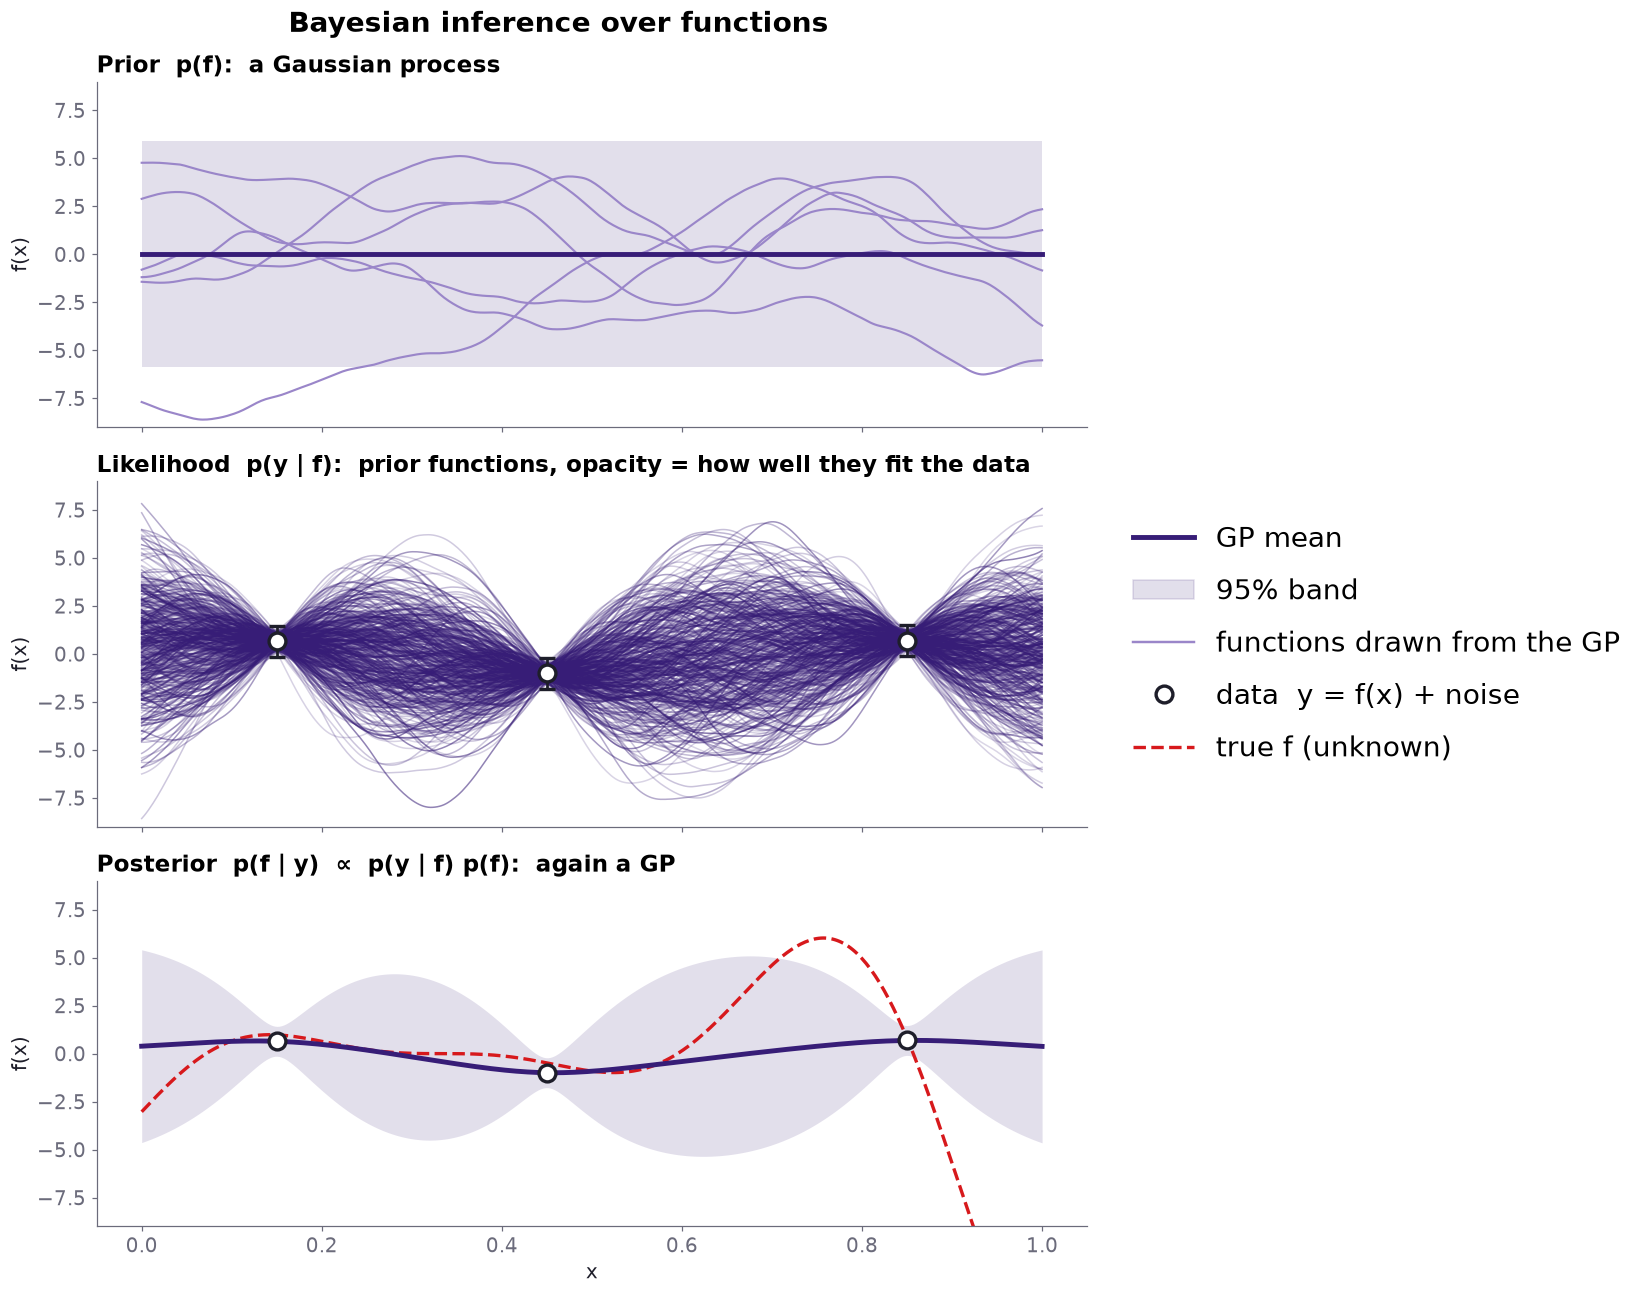

In [11]:
def draw_data(ax, with_bars=True):
    ax.errorbar(X_DATA, y_data, yerr=2 * LIKELIHOOD_NOISE_SD if with_bars else None, fmt="o", color=INK, mfc="white",
                mew=2.2, ms=11, capsize=5, elinewidth=1.8, zorder=6, label="data  y = f(x) + noise")

fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True, sharey=True)

# prior: the GP before any data
prior_axis = axes[0]
prior_axis.fill_between(GRID, -1.96 * SIGNAL_SD, 1.96 * SIGNAL_SD, color=PURPLE, alpha=0.14, lw=0, label="95% band")
for draw in all_draws[:6, len(X_DATA):]:
    prior_axis.plot(GRID, draw, color=PURPLE_LIGHT, lw=1.4, label="functions drawn from the GP" if draw is all_draws[0, len(X_DATA):] else None)
prior_axis.plot(GRID, np.zeros_like(GRID), color=PURPLE, lw=3.2, label="GP mean")
prior_axis.set_title("Prior  p(f):  a Gaussian process", loc="left")

# likelihood: the same prior draws, opacity proportional to how well they explain the data
likelihood_axis = axes[1]
best_first = np.argsort(weights)[::-1][:400]
for index in best_first:
    likelihood_axis.plot(GRID, all_draws[index, len(X_DATA):], color=PURPLE, lw=1.0, alpha=float(weights[index] / weights.max()) * 0.6)
draw_data(likelihood_axis)
likelihood_axis.set_title("Likelihood  p(y | f):  prior functions, opacity = how well they fit the data", loc="left")

# posterior: the exact GP posterior
posterior_axis = axes[2]
posterior_axis.fill_between(GRID, posterior_mean - 1.96 * posterior_sd, posterior_mean + 1.96 * posterior_sd, color=PURPLE, alpha=0.14, lw=0)
posterior_axis.plot(GRID, objective(GRID), color=RED, lw=2.2, ls="--", label="true f (unknown)")
posterior_axis.plot(GRID, posterior_mean, color=PURPLE, lw=3.2)
draw_data(posterior_axis, with_bars=False)
posterior_axis.set_title("Posterior  p(f | y)  ∝  p(y | f) p(f):  again a GP", loc="left")

for ax in axes:
    ax.set_ylabel("f(x)")
axes[-1].set_xlabel("x")
axes[0].set_ylim(-9, 9)
handles = [plt.Line2D([], [], color=PURPLE, lw=3.2), plt.Rectangle((0, 0), 1, 1, color=PURPLE, alpha=0.14),
           plt.Line2D([], [], color=PURPLE_LIGHT, lw=1.6), plt.Line2D([], [], color=INK, marker="o", mfc="white", mew=2.2, ms=11, ls=""),
           plt.Line2D([], [], color=RED, lw=2.2, ls="--")]
fig.legend(handles, ["GP mean", "95% band", "functions drawn from the GP", "data  y = f(x) + noise", "true f (unknown)"],
           loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=18, markerscale=1.0, handlelength=2.2, labelspacing=0.9)
fig.suptitle("Bayesian inference over functions", fontsize=18, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "bayes_basics.png", bbox_inches="tight")
plt.show()

## 6. Formula images for the pairwise GP slide

Each formula is written to `presentation_figs/formulas/` as its own PNG (black on white, LaTeX-style).

In [12]:
FORMULAS = FIGURES / "formulas"
FORMULAS.mkdir(exist_ok=True)

def render_formula(file_name, lines, font_size=34, line_height=1.25):
    # lines: mathtext strings drawn one under the other, centred; the image is cropped to the text
    with plt.rc_context({"mathtext.fontset": "cm"}):
        fig = plt.figure(figsize=(1, line_height * len(lines)))
        for row, line in enumerate(lines):
            size = font_size if row == 0 else 0.62 * font_size
            fig.text(0.5, 1 - (row + 0.5) / len(lines), line, ha="center", va="center", fontsize=size, color="black")
        fig.savefig(FORMULAS / file_name, bbox_inches="tight", pad_inches=0.25, facecolor="white", dpi=300)
        plt.close(fig)

UTILITY_DIFFERENCE = r"\dfrac{u(x_i) - u(x_i')}{\sqrt{2}}"
render_formula("likelihood.png", [rf"$P(r_i = 1 \mid u) \;=\; \Phi\left({UTILITY_DIFFERENCE}\right)$"])
render_formula("posterior.png", [r"$p(u \mid \mathcal{D}_r) \;\propto\; p(u)\;\prod_{i=1}^{m} P(r_i \mid u)$"])
render_formula("laplace.png", [r"$p(u \mid \mathcal{D}_r) \;\approx\; \mathcal{N}\left(\hat{u},\; (K^{-1} + \Lambda)^{-1}\right)$",
                               r"$\hat{u} = \mathrm{argmax}_u \, \log p(u \mid \mathcal{D}_r)$",
                               r"$\Lambda = -\nabla_u^2 \, \log p(\mathcal{D}_r \mid u)\ \ \mathrm{at}\ \ u = \hat{u}$"], line_height=1.0)
render_formula("prediction.png", [r"$P(x \succ x') \;=\; \Phi\left(\dfrac{m}{\sqrt{2 + v}}\right)$",
                                  r"$m,\ v:\ \mathrm{posterior\ mean\ and\ variance\ of}\ \ u(x) - u(x')$"], line_height=1.3)
print(sorted(path.name for path in FORMULAS.iterdir()))

['laplace.png', 'likelihood.png', 'posterior.png', 'prediction.png']


## Where the other pieces of the project already have plots

- **Pairwise GP** (learning a utility from comparisons): `preference_demo.ipynb`, section 6 (one dimension: certainty that $x \succ y$) and section 3 (2D, noise vs number of comparisons).
- **Probit score $\pi(x)$**: `preference_demo.ipynb`, section 4; `bo_loop_demo.ipynb`, 14c.
- **Soft Copeland score $C(x)$**: `preference_demo.ipynb`, "Soft-Copeland score" (just before section 5); `copeland_demo.ipynb`, "The Copeland score on its own" and "How the Copeland score is computed".
- **Acquisition = EI × preference score, inside the loop**: `bo_loop_demo.ipynb`, 14e (`plot_acquisition`); `copeland_demo.ipynb`, "The terms of the acquisition".